## Imports 

In [54]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interactive
from IPython.display import display
import pandas as pd




from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

from sklearn.model_selection import cross_val_score, KFold

## Data Collection (Loading the CSVs)

In [34]:
# Define your data path
data_dir = "../Data" # Update this to your folder path if needed

# 1. Load the raw datasets
stores_df = pd.read_csv(os.path.join(data_dir, 'stores.csv'))
readings_df = pd.read_csv(os.path.join(data_dir, 'energy_readings.csv'))
bills_df = pd.read_csv(os.path.join(data_dir, 'utility_bills.csv'))


print("Data loaded successfully!")
print(f"Stores count: {len(stores_df)}")
print(f"Energy readings count: {len(readings_df)}")
print(f"Utility bills count: {len(bills_df)}")

Data loaded successfully!
Stores count: 60
Energy readings count: 21900
Utility bills count: 1440


## Data Cleaning & Merging

In [35]:
# 2. Merge the three tables together on 'store_id'
merged_df = pd.merge(readings_df, stores_df, on='store_id', how='inner')
full_df = pd.merge(merged_df, bills_df, on='store_id', how='inner')

# Clean: Drop exact duplicate rows
initial_rows = len(full_df)
full_df = full_df.drop_duplicates()
cleaned_rows = len(full_df)

print(f"Removed {initial_rows - cleaned_rows} duplicate rows.")
print(f"Cleaned dataset total rows: {cleaned_rows}")

Removed 0 duplicate rows.
Cleaned dataset total rows: 525600


## FEATURE ENGINEERING (Analyst Role)

In [36]:
print("\n--- Phase 3: Feature Engineering ---")

# Group by store identifiers using your exact column names
store_features = full_df.groupby(['store_id', 'store_name', 'store_type', 'city']).agg({
    'electricity_kwh': 'sum',
    'total_amount': 'sum',
    'solar_generation_kwh': 'sum',
    'tariff_per_kwh': 'mean'
}).reset_index()

# Create advanced analytical features
store_features['net_energy_kwh'] = store_features['electricity_kwh'] - store_features['solar_generation_kwh']
store_features['effective_tariff'] = store_features['total_amount'] / store_features['electricity_kwh']

print("Feature engineering completed successfully!")
print(store_features.head(3))


--- Phase 3: Feature Engineering ---
Feature engineering completed successfully!
   store_id             store_name         store_type       city  \
0       101   Bangalore Whitefield  Convenience Store  Bangalore   
1       102  Bangalore Indiranagar        Supermarket  Bangalore   
2       103  Bangalore Koramangala        Supermarket  Bangalore   

   electricity_kwh  total_amount  solar_generation_kwh  tariff_per_kwh  \
0       2082219.12  6.221222e+08             260618.88         8.99500   
1       9565047.84  2.775817e+09                  0.00         8.74125   
2       9593142.00  2.792116e+09            1079922.72         8.82000   

   net_energy_kwh  effective_tariff  
0      1821600.24        298.778466  
1      9565047.84        290.204217  
2      8513219.28        291.053287  


In [37]:
full_df.columns


Index(['reading_id', 'store_id', 'reading_date', 'electricity_kwh',
       'water_liters', 'diesel_liters', 'solar_generation_kwh', 'store_name',
       'city', 'state', 'store_type', 'area_sqft', 'operating_hours',
       'opening_date', 'active', 'bill_id', 'billing_month', 'units_kwh',
       'tariff_per_kwh', 'fixed_charge', 'tax_amount', 'total_amount',
       'due_date', 'payment_status'],
      dtype='str')

## EXPLORATORY DATA ANALYSIS & Z-SCORES

In [38]:
print("\n--- Phase 4: Exploratory Data Analysis & Risk Flagging ---")

# Calculate Z-Scores based on total spend to flag high-risk outlier stores
mean_spend = store_features['total_amount'].mean()
std_spend = store_features['total_amount'].std()

store_features['z_score'] = (store_features['total_amount'] - mean_spend) / std_spend
store_features['risk_status'] = np.where(store_features['z_score'] > 1.5, 'High-Risk', 'Normal')

high_risk_count = len(store_features[store_features['risk_status'] == 'High-Risk'])
print(f"Total Enterprise Spend Analyzed: ₹{store_features['total_amount'].sum():,.2f}")
print(f"High-Risk Outlier Stores Flagged: {high_risk_count}")


--- Phase 4: Exploratory Data Analysis & Risk Flagging ---
Total Enterprise Spend Analyzed: ₹331,275,580,789.45
High-Risk Outlier Stores Flagged: 7


## PHASE 5: MODEL BUILDING & TRAINING

In [39]:
print("\n--- Phase 5: Training Machine Learning Model ---")

# Prepare features (X) and target (y)
# Convert categorical text columns (store_type, city) into numerical format using get_dummies
model_data = pd.get_dummies(store_features[['store_type', 'city', 'electricity_kwh', 'solar_generation_kwh', 'total_amount']], drop_first=True)

X = model_data.drop(columns=['total_amount']) # Features used to predict utility spend
y = model_data['total_amount']                # Target variable we want to forecast

# Split data: 80% for training the model, 20% for testing its accuracy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Model training complete!")


--- Phase 5: Training Machine Learning Model ---
Model training complete!


## MODEL EVALUATION & PREDICTION

In [40]:
print("\n--- Phase 6: Evaluation & Future Forecasting ---")

# Evaluate model performance on the test set
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Model Accuracy (R² Score): {r2:.2f} (1.0 is a perfect match)")
print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")

# Simulate predicting a future utility bill for a test case
sample_input = X_test.iloc[[0]]
predicted_spend = model.predict(sample_input)[0]
actual_spend = y_test.iloc[0]

print("\n--- Sample Prediction Test ---")
print(f"Predicted Utility Bill: ₹{predicted_spend:,.2f}")
print(f"Actual Utility Bill:    ₹{actual_spend:,.2f}")


--- Phase 6: Evaluation & Future Forecasting ---
Model Accuracy (R² Score): 0.93 (1.0 is a perfect match)
Mean Absolute Error (MAE): ₹492,940,092.60

--- Sample Prediction Test ---
Predicted Utility Bill: ₹588,893,977.41
Actual Utility Bill:    ₹622,122,235.20


## CROSS VALIDATION 

In [43]:
# 1. Set up 5-Fold Cross-Validation
# shuffle=True ensures data is mixed up before splitting
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Compute R-squared scores across all 5 folds
cv_r2_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

# Compute Mean Absolute Error (MAE) across folds as well
cv_mae_scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_absolute_error')

print("--- Cross-Validation Results ---")
print(f"R² Scores for each of the 5 folds: {cv_r2_scores}")
print(f"Average Cross-Validation R²: {cv_r2_scores.mean():.2f} (± {cv_r2_scores.std() * 2:.2f})")
print(f"Average Cross-Validation MAE: ₹{-cv_mae_scores.mean():,.2f}")

--- Cross-Validation Results ---
R² Scores for each of the 5 folds: [0.93140346 0.82083391 0.98123057 0.92835985 0.98644481]
Average Cross-Validation R²: 0.93 (± 0.12)
Average Cross-Validation MAE: ₹735,416,725.46


--- Top Features Driving Utility Spend Predictions ---
                   Feature  Importance
0          electricity_kwh    0.802663
1     solar_generation_kwh    0.115357
3   store_type_Hypermarket    0.061735
37              city_Salem    0.008704
16              city_Hubli    0.003187
15           city_Guwahati    0.001965
29             city_Mysore    0.001951
4   store_type_Supermarket    0.000866
30             city_Nagpur    0.000765
25           city_Ludhiana    0.000568


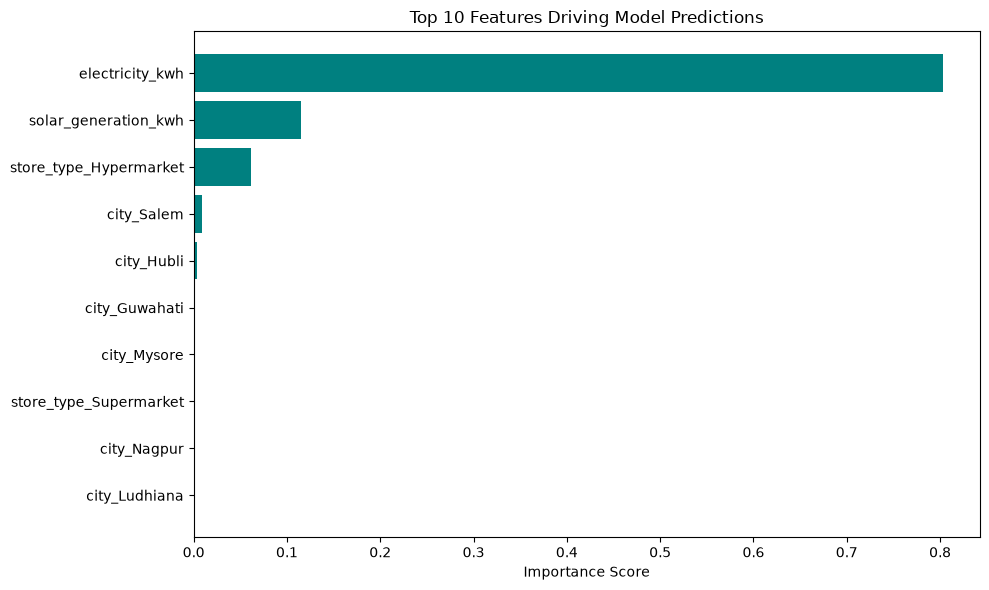

In [44]:
# 1. Extract feature importances from the trained Random Forest model
importances = model.feature_importances_
feature_names = X.columns

# 2. Create a clean summary DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("--- Top Features Driving Utility Spend Predictions ---")
print(feature_importance_df.head(10))

# 3. Plot the top features for a professional presentation
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'].head(10)[::-1], feature_importance_df['Importance'].head(10)[::-1], color='teal')
plt.xlabel("Importance Score")
plt.title("Top 10 Features Driving Model Predictions")
plt.tight_layout()
plt.show()

## Save the Model for Future Use (Model Persistence)

In [18]:
import joblib

# 1. Save the trained model and feature columns
joblib.dump(model, 'energy_model.pkl')
joblib.dump(X.columns, 'model_columns.pkl')

print("Model successfully saved as 'energy_model.pkl'!")
print("Model columns saved as 'model_columns.pkl'!")

Model successfully saved as 'energy_model.pkl'!
Model columns saved as 'model_columns.pkl'!


## Plot Actual vs. Predicted Utility Spend

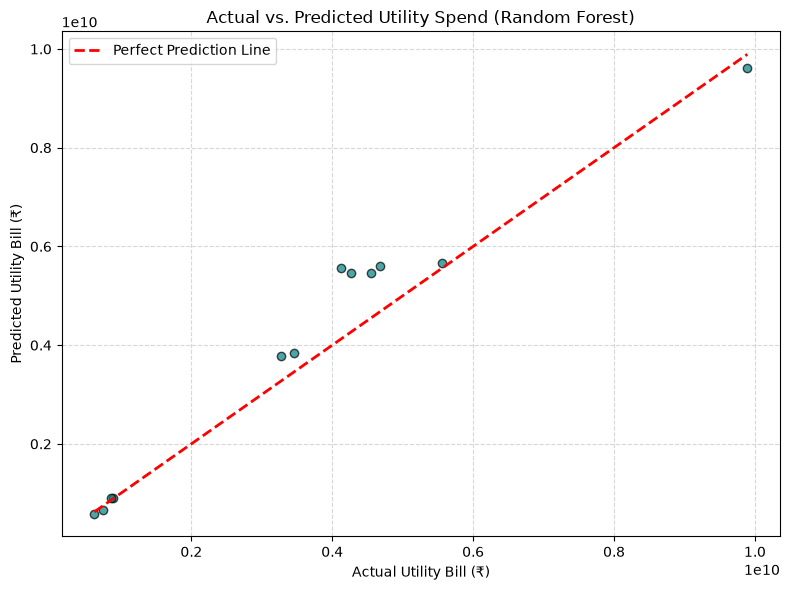

In [45]:


# 1. Create the comparison plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, color='teal', alpha=0.7, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction Line')

plt.xlabel("Actual Utility Bill (₹)")
plt.ylabel("Predicted Utility Bill (₹)")
plt.title("Actual vs. Predicted Utility Spend (Random Forest)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Export the Final Audit Dataset

In [46]:
# Add model predictions to your main dataframe
store_features['predicted_spend'] = model.predict(X)

# Export to CSV inside your Data folder
store_features.to_csv('../Data/predicted_store_audit.csv', index=False)
print("Final audit dataset exported successfully!")

Final audit dataset exported successfully!


In [47]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# 1. Create input widgets
store_type_dropdown = widgets.Dropdown(
    options=store_features['store_type'].unique(), 
    description='Store Type:'
)
city_dropdown = widgets.Dropdown(
    options=store_features['city'].unique(), 
    description='City:'
)
kwh_slider = widgets.FloatSlider(
    value=500000.0, min=1000.0, max=20000000.0, step=1000.0, 
    description='Electricity:'
)
solar_slider = widgets.FloatSlider(
    value=20000.0, min=0.0, max=5000000.0, step=500.0, 
    description='Solar:'
)

button = widgets.Button(description="Predict Utility Spend", button_style='success')

# Use an Output widget to safely handle dynamic updates
out = widgets.Output()

# 2. Define button click logic
def on_button_clicked(b):
    with out:
        clear_output(wait=True)
        # Build input template matching training columns
        input_dict = {col: 0 for col in X.columns}
        input_dict['electricity_kwh'] = kwh_slider.value
        input_dict['solar_generation_kwh'] = solar_slider.value
        
        st_col = f"store_type_{store_type_dropdown.value}"
        city_col = f"city_{city_dropdown.value}"
        
        if st_col in input_dict:
            input_dict[st_col] = 1
        if city_col in input_dict:
            input_dict[city_col] = 1
            
        input_df = pd.DataFrame([input_dict])
        prediction = model.predict(input_df)[0]
        
        print(f"🎯 Predicted Utility Bill Amount: ₹ {prediction:,.2f}")

button.on_click(on_button_clicked)

# Change this line at the bottom of your cell:
display(store_type_dropdown, city_dropdown, kwh_slider, solar_slider, button, out)

Dropdown(description='Store Type:', options=('Convenience Store', 'Supermarket', 'Hypermarket', 'Department St…

Dropdown(description='City:', options=('Bangalore', 'Mysore', 'Mangalore', 'Hubli', 'Belgaum', 'Chennai', 'Coi…

FloatSlider(value=500000.0, description='Electricity:', max=20000000.0, min=1000.0, step=1000.0)

FloatSlider(value=20000.0, description='Solar:', max=5000000.0, step=500.0)

Button(button_style='success', description='Predict Utility Spend', style=ButtonStyle())

Output()

In [55]:

def interactive_predict(store_type, city, electricity_kwh, solar_generation_kwh):
    # Build input template matching model training columns
    input_dict = {col: 0 for col in X.columns}
    input_dict['electricity_kwh'] = electricity_kwh
    input_dict['solar_generation_kwh'] = solar_generation_kwh
    
    st_col = f"store_type_{store_type}"
    city_col = f"city_{city}"
    
    if st_col in input_dict:
        input_dict[st_col] = 1
    if city_col in input_dict:
        input_dict[city_col] = 1
        
    input_df = pd.DataFrame([input_dict])
    prediction = model.predict(input_df)[0]
    
    print(f"🎯 Predicted Utility Bill Amount: ₹{prediction:,.2f}")

# Create the interactive dashboard cleanly without trailing text
dashboard = interactive(interactive_predict, 
                        store_type=store_features['store_type'].unique(), 
                        city=store_features['city'].unique(), 
                        electricity_kwh=(1000.0, 20000000.0, 10000.0), 
                        solar_generation_kwh=(0.0, 5000000.0, 5000.0))

display(dashboard)

interactive(children=(Dropdown(description='store_type', options=('Convenience Store', 'Supermarket', 'Hyperma…